# Problem 3

In [52]:
import numpy as np
import matplotlib.pyplot as plt

In [53]:
f = lambda beta: np.sin(beta) + beta / 10
df = lambda beta: np.cos(beta) + 1 / 10

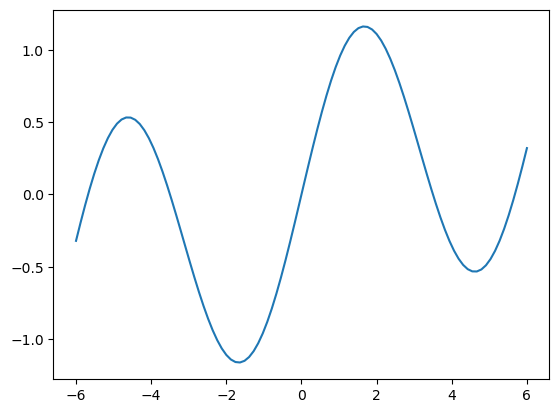

In [54]:
# 3a
x = np.linspace(-6, 6, 100)
y = f(x)

plt.plot(x, y)
plt.show()

In [55]:
def descend(beta, rho = 0.1, num_steps = 100):
    beta_history = [beta]
    for _ in range(num_steps):
        beta = beta - rho * df(beta)
        beta_history.append(beta)

    plt.plot(x, y)
    plt.plot(beta_history, f(np.array(beta_history)), 'ro-')
    plt.plot(beta_history[-1], f(beta_history[-1]), 'bo')
    plt.title(f'Gradient Descent ends at {beta_history[-1]:.2f}')
    plt.show()

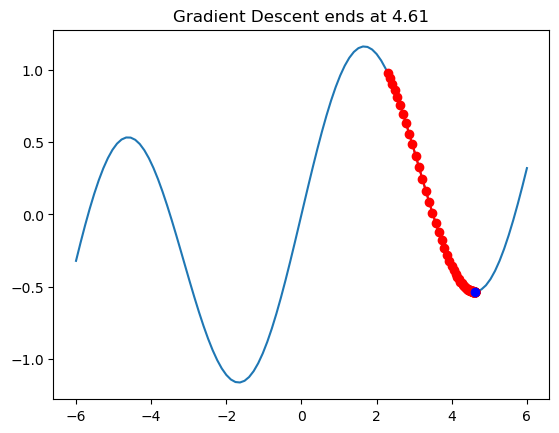

In [56]:
# 3c
descend(2.3)

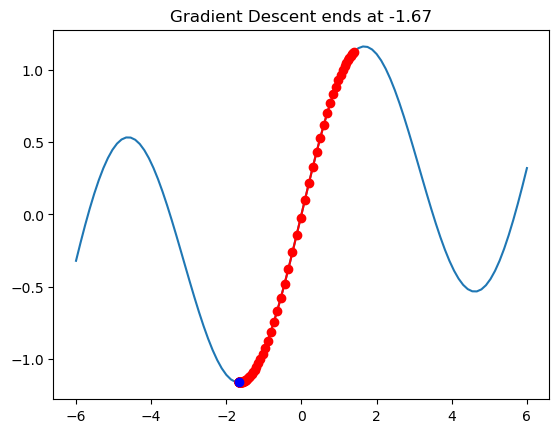

In [57]:
# 3d
descend(1.4)

# Problem 4

In [58]:
# Problem 4
from ISLP import load_data
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

data = load_data('Default')

In [59]:
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def train_and_plot(X, y):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)

    nn = MLPClassifier(hidden_layer_sizes=(10,), alpha=0.01, max_iter=500, random_state=42)
    lr = LogisticRegression(max_iter=500, random_state=42)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    labels = ['No', 'Yes']

    for i, model in enumerate([nn, lr]):
        model.fit(X_train_s, y_train)
        y_pred = model.predict(X_test_s)
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        cm = confusion_matrix(y_test, y_pred)
        
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                    xticklabels=labels, yticklabels=labels)
        axes[i].set_title(f'{model.__class__.__name__} Accuracy: {accuracy * 100:.2f}%, \nPrecision: {precision * 100:.2f}%, Recall: {recall * 100:.2f}%, F1: {f1 * 100:.2f}%')
        axes[i].set_xlabel('Predicted')
        axes[i].set_ylabel('True')

    fig.tight_layout()
    plt.show()

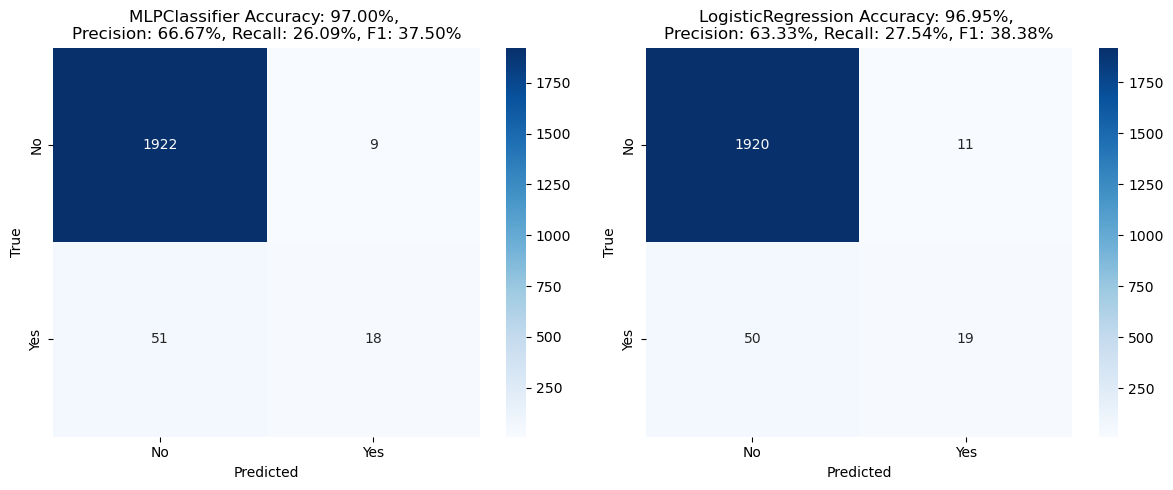

In [60]:
y = (data['default'] == 'Yes').astype(int)
X = data[['student', 'balance', 'income']].copy()
X['student'] = (X['student'] == 'Yes').astype(int)

train_and_plot(X, y)

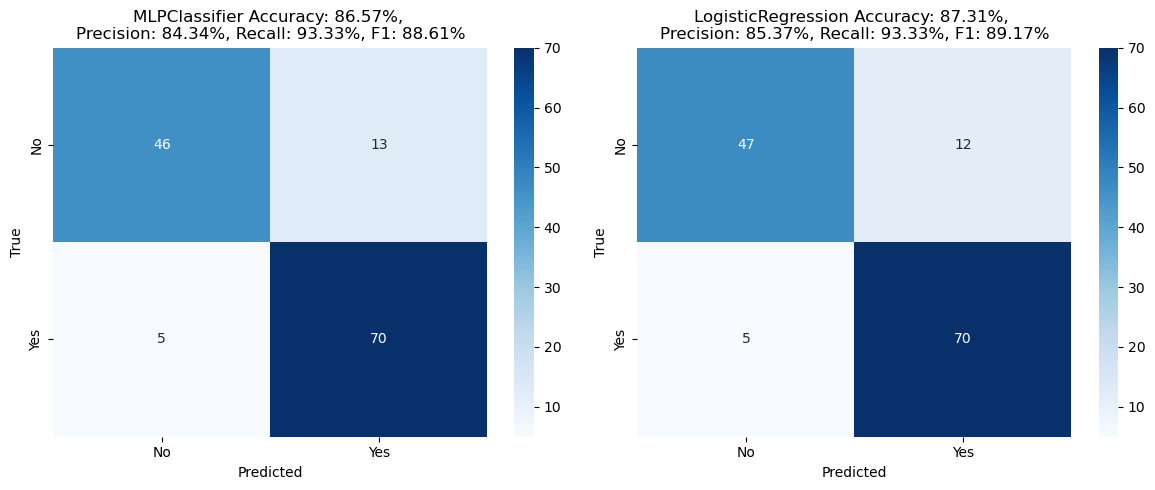

In [61]:
import pandas as pd

# balance classes
defaults = data[data['default'] == 'Yes']
non_defaults = data[data['default'] == 'No']
non_defaults = non_defaults.sample(len(defaults), random_state=42)
data_balanced = pd.concat([defaults, non_defaults])

yb = (data_balanced['default'] == 'Yes').astype(int)
Xb = data_balanced[['student', 'balance', 'income']].copy()
Xb['student'] = (Xb['student'] == 'Yes').astype(int)

train_and_plot(Xb, yb)